Spectrum of Sodium-22

In [393]:
import matplotlib.pyplot as plt
import numpy as np
from lmfit import models


In [394]:
with open("spectrum_paddenstoelen_231126.csv", "r") as file:
    full_pulseheight = []
    full_counts = []
    i = 0

    for line in file:
        data = line.split(',')

        if i > 0:
            full_pulseheight.append(float(data[0]))
            full_counts.append(float(data[1]))
        else:
            i+=1


In [395]:
pulseheight = []
counts = []
for i in range(129):
    if full_pulseheight[i] > 0:
        pulseheight.append(full_pulseheight[i])
        counts.append(full_counts[i])

In [396]:
# h to E 
a = 0.3289253213202916
a_err = 0.04530554546847939
b = 26.031476080458457

def h_to_E(x):
    x_array = np.array(x)
    
    y = 1/a * x_array - b/a 
    y_list = list(y)
    return y_list

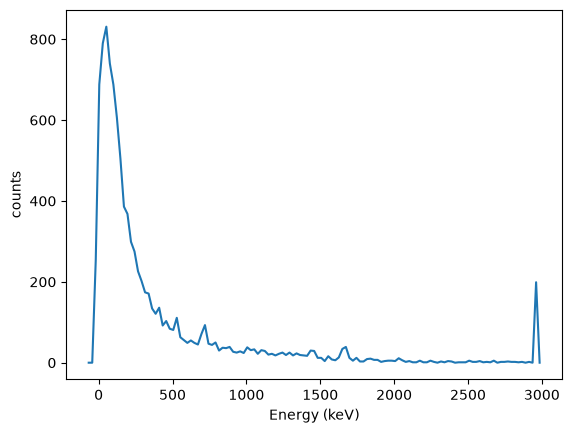

In [397]:
Energy = h_to_E(pulseheight)

plt.plot(Energy, counts)
plt.xlabel("Energy (keV)")
plt.ylabel("counts")
plt.show()

In [398]:
def lorentzian(x, x0, a, gam ):
  return a * gam**2 / ( gam**2 + ( x - x0 )**2)

def multiple_lorentzian(x, x01, a1, gam1, x02, a2, gam2, x03, a3, gam3):#, x04, a4, gam4):
    return lorentzian(x, x01, a1, gam1) + lorentzian(x, x02, a2, gam2) + lorentzian(x, x03, a3, gam3) #+ lorentzian(x, x04, a4, gam4)

In [399]:
spectrum = models.Model(multiple_lorentzian)
fit_result = spectrum.fit(counts, x=Energy, x01=650, a1=100, gam1=10, x02=1650, a2=200, gam2=10, x03=650, a3=100, gam3=10)

print(fit_result.fit_report())

[[Model]]
    Model(multiple_lorentzian)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 2744
    # data points      = 129
    # variables        = 9
    chi-square         = 1294751.87
    reduced chi-square = 10789.5989
    Akaike info crit   = 1206.60822
    Bayesian info crit = 1232.34653
    R-squared          = 0.63301413
[[Variables]]
    x01:  -2745.02155 +/- 2485070.23 (90530.08%) (init = 650)
    a1:    77029.9522 +/- 4.5839e+09 (5950781.42%) (init = 100)
    gam1:  280.536529 +/- 8123472.47 (2895691.52%) (init = 10)
    x02:   706.695519 +/- 1163.01663 (164.57%) (init = 1650)
    a2:   -289.772691 +/- 4307.76880 (1486.60%) (init = 200)
    gam2: -727.562799 +/- 3529.96926 (485.18%) (init = 10)
    x03:   171132.953 +/- 1.8225e+11 (106498327.96%) (init = 650)
    a3:   -58734.0705 +/- 2.0756e+13 (35338672196.21%) (init = 100)
    gam3: -9234.01246 +/- 1.6265e+12 (17614269718.30%) (init = 10)
[[Correlations]] (unreported correlations are < 0.100)
 

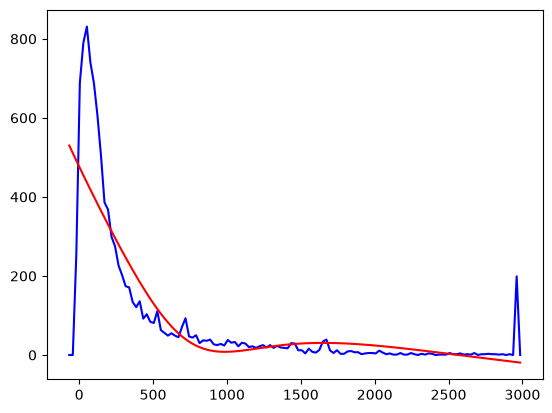

In [400]:
plt.plot(Energy, counts, 'b-')
plt.plot(Energy, fit_result.best_fit, 'r-')

plt.show()

In [401]:
spectrum = models.Model(multiple_lorentzian)
fit_result = spectrum.fit(counts, x=pulseheight, x01=-13, a1=200, gam1=10, x02=572, a2=200, gam2=10, x03=259, a3=200, gam3=10)

print(fit_result.fit_report())

[[Model]]
    Model(multiple_lorentzian)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 3981
    # data points      = 129
    # variables        = 9
    chi-square         = 1209759.93
    reduced chi-square = 10081.3328
    Akaike info crit   = 1197.84949
    Bayesian info crit = 1223.58780
    R-squared          = 0.65710434
[[Variables]]
    x01:  -2088.54338 +/- 57771.1372 (2766.10%) (init = -13)
    a1:    51697.3707 +/- 92736098.9 (179382.62%) (init = 200)
    gam1: -295.218744 +/- 262488.813 (88913.33%) (init = 10)
    x02:   510.480950 +/- 982.060322 (192.38%) (init = 572)
    a2:   -601.646845 +/- 5015.59109 (833.64%) (init = 200)
    gam2:  766.243904 +/- 2921.93625 (381.33%) (init = 10)
    x03:   218.126829 +/- 34.3715847 (15.76%) (init = 259)
    a3:   -261.730126 +/- 333.482230 (127.41%) (init = 200)
    gam3: -119.914132 +/- 117.328890 (97.84%) (init = 10)
[[Correlations]] (unreported correlations are < 0.100)
    C(a1, gam1)   = +1.0000
   

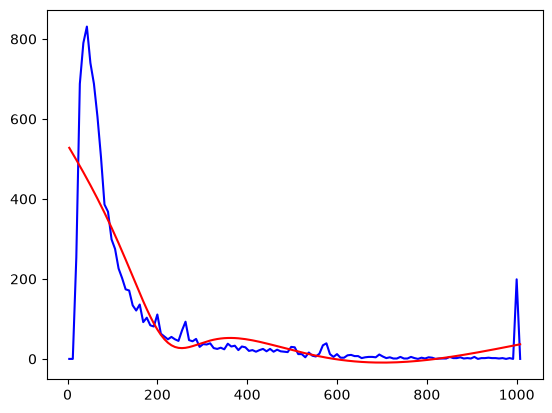

In [402]:
plt.plot(pulseheight, counts, 'b-')
plt.plot(pulseheight, fit_result.best_fit, 'r-')

plt.show()

In [403]:
pulseheight1 = fit_result.params['x01'].value
pulseheight2 = fit_result.params['x02'].value
pulseheight3 = fit_result.params['x03'].value

err_1 = fit_result.params['x01'].stderr
err_2 = fit_result.params['x02'].stderr
err_3 = fit_result.params['x03'].stderr

In [404]:
# h to E 
a = 0.3289253213202916
a_err = 0.04530554546847939
b = 26.031476080458457

def function(x, x_err):
    y = 1/a * x - b/a 

    y_err = np.sqrt((a_err/a)**2 + (x_err/x)) * y
    y_err = float(y_err)
    return y, y_err

In [405]:
print(function(pulseheight2, err_2))
print(function(pulseheight3, err_3))
Energy, E_err = function(pulseheight3, err_3)

(1472.8251148186257, 2052.8699284203794)
(584.0090161888838, 245.3866102707901)


In [406]:
E_min = Energy - E_err
E_max = Energy + E_err
print(E_min, E_max)

338.6224059180937 829.395626459674
